In [1]:
"""Scripts for analyzing of phantom outputs.

This script calc APR-related outputs.


-------------------------------------------------------------------------------

Side note: Remember to limit line length to 79 characters according to PEP-8
    https://peps.python.org/pep-0008/#maximum-line-length    
which is the length of below line of '-' characters.

-------------------------------------------------------------------------------

"""

"Scripts for analyzing of phantom outputs.\n\nThis script calc APR-related outputs.\n\n\n-------------------------------------------------------------------------------\n\nSide note: Remember to limit line length to 79 characters according to PEP-8\n    https://peps.python.org/pep-0008/#maximum-line-length    \nwhich is the length of below line of '-' characters.\n\n-------------------------------------------------------------------------------\n\n"

.

## Def

.

In [2]:
import numpy as np
import numpy.typing as npt
from numpy import pi
from astropy import units
from astropy import constants as const
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.typing import ColorType
import matplotlib as mpl
from numba import jit,njit, prange
import sarracen
import itertools
from scipy import integrate, fft
from scipy.spatial import KDTree
from scipy.optimize import curve_fit
from datetime import datetime
import os
from os.path import sep
# fix weird moviepy cannot find my ffmpeg exe error
try: import moviepy
except RuntimeError: os.environ["IMAGEIO_FFMPEG_EXE"] = "/usr/bin/ffmpeg"
try: from moviepy import ImageSequenceClip, concatenate_videoclips
except ImportError: from moviepy.editor import ImageSequenceClip, concatenate_videoclips
import gc
#from os import path

In [3]:
# import my modules listed in ./main/

import clmuphantomlib as mupl
from clmuphantomlib            import MyPhantomDataFrames, get_eos, get_eos_opacity, get_col_kernel_funcs
from clmuphantomlib.log        import is_verbose, say
from clmuphantomlib.settings   import DEFAULT_SETTINGS as settings
from clmuphantomlib.units_util import get_val_in_unit, set_as_quantity #, get_units_field_name, get_units_cgs
from clmuphantomlib.io         import json_dump, json_load, hdf5_dump, hdf5_load
from clmuphantomlib.eos.mesa   import EoS_MESA_opacity
from clmuphantomlib.light      import get_optical_depth_by_ray_tracing_3D, get_photosphere_on_ray

from multiprocessing import cpu_count, Pool #Process, Queue
NPROCESSES = 1 if cpu_count() is None else max(cpu_count(), 1)

In [4]:
# settings
#
#   imported from script_input.py file


from script_LCGen__input import verbose, verbose_loop, interm_dir, output_dir, unitsOut, SPEC_DIST, PHOTOSPHERE_TAU, JOB_PROFILES_DICT
from script_LCGen import get_sph_neighbours
from _sharedFuncs import mpdf_read, pa_read_energy, pa_read_ev

# remove temp flag
interm_dir = interm_dir.split('test_')[0]
interm_dir = interm_dir.split('Tscale_')[0]
interm_dir = interm_dir.split('Tcut_')[0]
interm_dir = interm_dir.split('Tdelete_')[0]
# interm_dir = interm_dir.split('olim_')[0]


unitsOutTxt = {  key  : unitsOut[key].to_string('latex_inline') for key in unitsOut.keys() }

spec_dist = SPEC_DIST

# set metadata
with open("_metadata__input.json", 'r') as f:
    metadata = json_load(f)
metadata['Title'] = "Getting light curves by intergrating across a grid of rays"
metadata['Description'] = f"""Getting light curves by intergrating across a grid of rays with the same directions
for dump file data generated by phantom
"""


plt.rcParams.update({'font.size': 20})
if __name__ == '__main__' and is_verbose(verbose, 'note'):
    # remember to check if name is '__main__' if you wanna say anything
    #    so when you do multiprocessing the program doesn't freak out
    say('note', None, verbose, f"{interm_dir = }")
    say('note', None, verbose, f"Will use {NPROCESSES} processes for parallelization")


*   Note   :    run_ast_nodes() ==> run_code() ==> <module>():
	interm_dir = '../interm/'
*   Note   :    run_ast_nodes() ==> run_code() ==> <module>():
	Will use 8 processes for parallelization


In [5]:
from clmuphantomlib.log import say, is_verbose
from clmuphantomlib.geometry import get_dist2_between_2pt, get_closest_pt_on_line
from clmuphantomlib.sph_interp import get_sph_interp, get_h_from_rho, get_no_neigh, _get_sph_interp_phantom_np
from clmuphantomlib.units_util import set_as_quantity, set_as_quantity_temperature, get_units_field_name, DEFAULT_UNITS
from clmuphantomlib.eos   import EoS_Base
from clmuphantomlib.light import integrate_along_ray_grid, integrate_along_ray_gridxy

#  import (general)
import numpy as np
import numba
from numba import jit, njit, prange
import sarracen
from scipy.stats import linregress

from clmuphantomlib.geometry import get_dist2_from_pts_to_line, get_dist2_from_pt_to_line_nb, get_ray_unit_vec, get_rays_unit_vec

In [6]:
def xyz_to_rtp(xyzs):
    """Convert castesian coordinates to spherical coordinates"""
    rs = np.sqrt(np.sum(xyzs**2, axis=1))
    thetas = np.acos(xyzs[:, 2] / rs)
    phis = np.atan2(xyzs[:, 1], xyzs[:, 0])
    return rs, thetas, phis

def rtp_to_xyz(rs, thetas, phis):
    """Convert spherical coordinates to castesian coordinates"""
    xs = rs * np.sin(thetas) * np.cos(phis)
    ys = rs * np.sin(thetas) * np.sin(phis)
    zs = rs * np.cos(thetas)
    return np.stack((xs, ys, zs), axis=1)

In [7]:
output_dir = f"..{sep}fig{sep}20261013_APR-analysis{sep}"
output_dir

'../fig/20261013_APR-analysis/'

## Main

### MESA Stellar Stability

#### Functions

In [8]:
# utlities

def val_and_std(
    data: units.Quantity,
    weights: npt.NDArray|units.Quantity = None,
    to_unit: None|units.Unit = None,
) -> dict[str, units.Quantity]:
    
    if to_unit is None:
        to_unit = in_unit

    average = np.average(data, weights=weights)
    variance = np.average((data-average)**2, weights=weights)
    return average.to(to_unit), np.sqrt(variance).to(to_unit)


In [9]:
# Plot density profile

def _plot_rho_vs_rcom(
    mpdf,
    figax: None|tuple[mpl.figure.Figure, mpl.axes.Axes] = None,
    unitsOut: dict[str, units.Unit] = {
        'dist': units.Rsun,
        'density': units.g / units.cm**3,
    },
    xlims: None|tuple[float, float] = (1, 10000),
    ylims: None|tuple[float, float] = (1e-20, 1e-4),
    r0: None|units.Quantity = None,
    do_xlabel: bool = True,
    do_ylabel: bool = True,
    do_legend: bool = True,
    verbose: bool = True,
):
    
    fig, ax = plt.subplots(figsize=(10, 8)) if figax is None else figax

    sdf = mpdf.data['gas'].copy()

    use_apr: bool = True
    if 'apr_level' not in sdf:
        sdf['apr_level'] = 1
    if len(sdf['apr_level'].unique()) <= 1:
        use_apr = False
    
    for lv in sorted(sdf['apr_level'].unique()):
        mask = sdf['apr_level'] == lv
        
        x = set_as_quantity(sdf['RCoM'][mask], mpdf.units['dist']).to(unitsOut['dist'])
        y = set_as_quantity(sdf['rho'][mask], mpdf.units['density']).to(unitsOut['density'])
        ax.loglog(x, y, '.', color=f"C{lv}", label=f"APR lv{lv}" if use_apr else None)

    if r0 is not None:
        frac_outside_r0 = sdf[set_as_quantity(sdf['RCoM'], mpdf.units['dist']) > r0]['mass'].sum() / sdf['mass'].sum()
        if verbose: print(f"\t{frac_outside_r0*100:.1f} % of gas mass are outside {r0} radius.")
        ax.vlines(r0.to_value(unitsOut['dist']), ylims[0], ylims[1], linestyle='--', color='grey', alpha=0.5)
        ax.text(
            0.99, 0.98,
            f"Time = {mpdf.get_time():.1f}\n$f_\\text{{out}}$ = {frac_outside_r0*100:.1f} %",
            ha='right', va='top', transform=ax.transAxes)

    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    if do_xlabel: ax.set_xlabel(f"Radius / {unitsOut['dist'].to_string('latex_inline')}")
    if do_ylabel: ax.set_ylabel(f"Density / {unitsOut['density'].to_string('latex_inline')}")
    if do_legend: ax.legend()

    return fig, ax

In [17]:
# plot the density profile as a wall of panels

def plot_rho_vs_rcom_panels(
    job_nicknames: list[str] = ['2m-star--np1376256', '2ma-star--mfrac-p2-08', '2ma-star--mfrac-p2-10', '2ma-star--mfrac-p2-12'],
    file_indexes: list[int] = [0, 400, 700],
    unitsOut: dict[str, units.Unit] = {
        'time': units.yr,
        'dist': units.Rsun,
        'density': units.g / units.cm**3,
    },
    r0: None|units.Quantity = None,
    output_dir: str = output_dir,
    verbose: bool = True,
):

    mpdf = None
    do_set_r0: bool = True if r0 is None else False
    
    nrow, ncol = len(file_indexes), len(job_nicknames)
    fig, axes = plt.subplots(nrow, ncol, figsize=(1+4*ncol, 1+3*nrow), sharex=True, sharey=True, squeeze=False)
    fig.subplots_adjust(hspace=0.0, wspace=0.0)
    
    for ijob, nn in enumerate(job_nicknames):
        job_profile = JOB_PROFILES_DICT[nn]
        job_name    = job_profile['job_name']
        params      = job_profile['params']
        ieos = job_profile['ieos']
        eos_opacity = EoS_MESA_opacity(params, settings)
        for ifile, file_index in enumerate(file_indexes):
            ax = axes[ifile, ijob]
            mpdf = mpdf_read(job_name, file_index, mpdf=mpdf, ieos=ieos, params=params, reset_xyz_by='CoM', calc_params=[], verbose=1)
            mpdf.data['gas']['RCoM'] = (mpdf.data['gas'][['x', 'y', 'z']]**2).sum(axis=1)**0.5
            if do_set_r0 and file_index == 0:
                r0 = set_as_quantity(mpdf.data['gas']['RCoM'].max(), mpdf.units['dist']).to(unitsOut['dist'])
                
            _plot_rho_vs_rcom(
                mpdf,
                figax = (fig, ax),
                unitsOut = unitsOut,
                r0 = set_as_quantity(r0, mpdf.units['dist']).to(unitsOut['dist']),
                xlims = (2, 2e4),
                ylims = (1e-18, 1e-2),
                do_xlabel = False, #ifile == nrow-1,
                do_ylabel = False, #ijob  == 0,
                do_legend = False,
                verbose = verbose,
            )

    fig.supxlabel(f"Radius / {unitsOut['dist'].to_string('latex_inline')}", y=0.03)
    fig.supylabel(f"Density / {unitsOut['density'].to_string('latex_inline')}", x=0.04)
    if output_dir is not None:
        outfig_filename = f"{output_dir}{sep}DensityProfile.png"
        fig.savefig(outfig_filename)
        if verbose: print(f"\tSaved to '{outfig_filename}'.")

    return fig, axes

In [11]:
# calc / load radius etc. info

def calc_star_stability(
    job_nicknames: list[str] = [],
    unitsOut: dict[str, units.Unit] = {
        'time': units.yr,
        'dist': units.Rsun,
        'density': units.g / units.cm**3,
    },
    load_existing_interm: bool = True,
    interm_dir: str = interm_dir,
    output_dir: str = output_dir,
    do_and_save_density_profile_plot: bool = True,
    verbose: bool = True,
):
    """Calc star radius for stability analysis.

    Note: file_index in job profiles implied by job_nicknames must contain 0 (to estabilish initial surface density rho0)
    """
    # data combined
    dc: dict = {}
    save_filename: str = f"{interm_dir}StellarStability.json"
    if load_existing_interm:
        try:
            with open(save_filename, 'r') as fp:
                dc = json_load(fp, load_metadata=False)
                if verbose: print(f"Loaded {dc.keys()} from '{save_filename}'.")
        except BaseException as e:
            print(f"*** Error: {e}")
            dc = {}
    
    for nn in job_nicknames:
        job_profile = JOB_PROFILES_DICT[nn]
        job_name    = job_profile['job_name']
        params      = job_profile['params']
        file_indexes = job_profile['file_indexes']
        ieos = job_profile['ieos']
        eos_opacity = EoS_MESA_opacity(params, settings)
    
        mpdf = None
        rho0: float = np.nan
        r0: float = np.nan
        dc[nn] = {
            'rho0': np.nan * unitsOut['density'],
            'r0': np.nan * unitsOut['dist'],
            'times': np.full(len(file_indexes), np.nan) * unitsOut['time'],
            'fracs_outside_r0': np.full(len(file_indexes), np.nan),  # * units.dimensionless_unscaled,
            'rs_part_val': np.full(len(file_indexes), np.nan) * unitsOut['dist'],
            'rs_part_std': np.full(len(file_indexes), np.nan) * unitsOut['dist'],
            'rs_dens_val': np.full(len(file_indexes), np.nan) * unitsOut['dist'],
            'rs_pdens_val': np.full(len(file_indexes), np.nan) * unitsOut['dist'],
            'rs_pdens_std': np.full(len(file_indexes), np.nan) * unitsOut['dist'],
        }
        
        for ifile, file_index in enumerate(file_indexes):

            plt.close('all')
            mpdf = mpdf_read(
                job_name, file_index, eos_opacity,
                mpdf=mpdf, params=job_profile['params'], ieos=ieos, reset_xyz_by='CoM', calc_params=[], verbose=1)
            if verbose: print(f"{nn}  {file_index:5d}", end='\t')

            mpdf.data['gas']['RCoM'] = (mpdf.data['gas'][['x', 'y', 'z']]**2).sum(axis=1)**0.5

            sdf_sorted = mpdf.data['gas'].sort_values(by='RCoM')
            totmass = sdf_sorted['mass'].sum()
            sdf_sorted['mcoord'] = sdf_sorted['mass'].cumsum()
            sdf_sorted['mfrac'] = sdf_sorted['mcoord'] / totmass
            
            # meta
            if ifile == 0:
                rho0 = np.min(sdf_sorted['rho'].min())
                r0 = sdf_sorted['RCoM'].iloc[-1]
                dc[nn]['rho0'] = set_as_quantity(rho0, mpdf.units['density']).to(unitsOut['density'])
                dc[nn]['r0'] = set_as_quantity(r0, mpdf.units['dist']).to(unitsOut['dist'])

            dc[nn]['times'][ifile] = mpdf.get_time()

            # fractions outside

            frac_outside_r0 = sdf_sorted[sdf_sorted['RCoM'] > r0]['mass'].sum() / totmass
            dc[nn]['fracs_outside_r0'][ifile] = frac_outside_r0

            # particle radius
            mask = sdf_sorted['mfrac'] > 0.995
            r_part_val, r_part_std = val_and_std(
                set_as_quantity(sdf_sorted['RCoM'][mask], mpdf.units['dist']),
                weights = sdf_sorted['mass'][mask],
                to_unit = unitsOut['dist'])
            dc[nn]['rs_part_val'][ifile] = r_part_val
            dc[nn]['rs_part_std'][ifile] = r_part_std

            # particle density radius
            mask = sdf_sorted['rho'] > rho0
            mass = np.where(mask, sdf_sorted['mass'], 0)
            mfrac = np.cumsum(mass) / np.sum(mass)
            mask = mask & (mfrac > 0.995)
            r_pdens_val, r_pdens_std = val_and_std(
                set_as_quantity(sdf_sorted['RCoM'][mask], mpdf.units['dist']),
                weights = sdf_sorted['mass'][mask],
                to_unit = unitsOut['dist'])
            dc[nn]['rs_pdens_val'][ifile] = r_pdens_val
            dc[nn]['rs_pdens_std'][ifile] = r_pdens_std
            
            # density radius
            mask = sdf_sorted['rho'] > rho0
            r_dens_val = set_as_quantity(
                (3 / (4*pi) *  np.sum(sdf_sorted['mass'][mask] / sdf_sorted['rho'][mask])) ** (1/3), mpdf.units['dist']
            ).to(unitsOut['dist'])
            dc[nn]['rs_dens_val'][ifile] = r_dens_val
            if verbose:
                print(
                    f"r_part = {r_part_val.value:7.1f} +/- {r_part_std.value:5.1f} {r_part_val.unit};",
                    f"r_pdens = {r_pdens_val.value:7.1f} +/- {r_pdens_std.value:5.1f} {r_pdens_val.unit};",
                    f"{r_dens_val = :.1f}", sep="\t")

            if do_and_save_density_profile_plot:
                fig, ax = _plot_rho_vs_rcom(
                    mpdf,
                    unitsOut = unitsOut,
                    r0 = set_as_quantity(r0, mpdf.units['dist']).to(unitsOut['dist']),
                    verbose = verbose,
                )
                outfig_filename = f"{output_dir}{sep}density-profiles{sep}{nn}_{file_index:05d}_rho-vs-RCoM.png"
                fig.savefig(outfig_filename)
                if verbose: print(f"\tSaved to '{outfig_filename}'.")
                fig.clf()
                plt.close(fig)
                del fig, ax
                gc.collect()

        if job_nicknames:    # proxy for done calc and gen-ed new interm data
            if not load_existing_interm:
                print(f"**  Warning: Overwriting existing interm data file '{save_filename}'.")
            with open(save_filename, 'w') as fp:
                json_dump(dc, fp)
                if verbose: print(f"Saved to '{save_filename}'.")
    return dc

In [12]:
# Plot density profile

def _plot_X_vs_times(
    dc,
    what: str,
    ylabel: None|str = None,
    job_nicknames: None|list[str] = None,
    figax: None|tuple[mpl.figure.Figure, mpl.axes.Axes] = None,
    unitsOut: dict[str, units.Unit] = {
        'time': units.yr,
        'dist': units.Rsun,
    },
    xlims: None|tuple[float, float] = (0, 20),
    ylims: None|tuple[float, float] = None,
    output_dir: None|str = None,
    verbose: bool = True,
):
    
    fig, ax = plt.subplots(figsize=(10, 8)) if figax is None else figax
    job_nicknames = list(dc.keys()) if job_nicknames is None else job_nicknames

    for i, nn in enumerate(job_nicknames):

        job_profile = JOB_PROFILES_DICT[nn]
        description = job_profile['name']
        color = f"C{i}"
        
        x = dc[nn]['times']
        y = dc[nn][what]
        if what in {'fracs_outside_r0'}:
            y = (y * units.dimensionless_unscaled).to(units.percent)
        ax.plot(x, y, color=color, label=description)
        if what in {'rs_part_val', 'rs_pdens_val'}:
            yerr = dc[nn][f"{what[:-3]}std"]
            ax.fill_between(x.value, (y-yerr).value, (y+yerr).value, color=color, alpha=0.15)


    ax.set_xlim(xlims)
    ax.set_ylim(ylims)
    ax.set_xlabel(f"Time / {x.unit.to_string('latex_inline')}")
    ylabel = what if ylabel is None else ylabel
    ax.set_ylabel(f"{ylabel} / {y.unit.to_string('latex_inline')}" if isinstance(y, units.Quantity) else ylabel)
    ax.legend()

    if output_dir is not None:
        outfig_filename = f"{output_dir}{sep}{ylabel.replace(' ', '')}.png"
        fig.savefig(outfig_filename)
        if verbose: print(f"\tSaved to '{outfig_filename}'.")
    return fig, ax

In [19]:
# plot all stellar stabilities plots (vs time)

def plot_X_vs_times_all(dc, output_dir=output_dir):

    fig, ax = _plot_X_vs_times(dc, 'rs_part_val', ylabel="Particle Radius", xlims=(0, 5), ylims=(200, 2000), output_dir=output_dir)
    fig, ax = _plot_X_vs_times(dc, 'rs_pdens_val', ylabel="Particle Density Radius", xlims=(0, 5), ylims=None, output_dir=output_dir)
    fig, ax = _plot_X_vs_times(dc, 'rs_dens_val', ylabel="Density Radius", xlims=(0, 5), ylims=None, output_dir=output_dir)
    fig, ax = _plot_X_vs_times(dc, 'fracs_outside_r0', ylabel="Mass Fraction Outside", xlims=(0, 5), ylims=(0, 10), output_dir=output_dir)
    plt.close('all')

#### Execution

In [14]:
# inputs
job_nicknames = ['2m-star--np172032', '2m-star--np1376256', '2ma-star--mfrac-p2-08', '2ma-star--mfrac-p2-10', '2ma-star--mfrac-p2-12',]
job_nicknames = []   # disable re-calc, load only

In [15]:
# calc / load star stability data
dc = calc_star_stability(job_nicknames, load_existing_interm=True, do_and_save_density_profile_plot=False)

Loaded dict_keys(['2m-star--np172032', '2m-star--np1376256', '2ma-star--mfrac-p2-12', '2ma-star--mfrac-p2-10', '2ma-star--mfrac-p2-08']) from '../interm/StellarStability.json'.


In [20]:
# plot
plot_X_vs_times_all(dc)

	Saved to '../fig/20261013_APR-analysis//ParticleRadius.png'.
	Saved to '../fig/20261013_APR-analysis//ParticleDensityRadius.png'.
	Saved to '../fig/20261013_APR-analysis//DensityRadius.png'.
	Saved to '../fig/20261013_APR-analysis//MassFractionOutside.png'.


	0.0 % of gas mass are outside 257.3856164523362 solRad radius.
	2.3 % of gas mass are outside 257.3856164523362 solRad radius.
	4.5 % of gas mass are outside 257.3856164523362 solRad radius.
	0.0 % of gas mass are outside 269.65954698284463 solRad radius.
	1.5 % of gas mass are outside 269.65954698284463 solRad radius.
	4.4 % of gas mass are outside 269.65954698284463 solRad radius.
	0.0 % of gas mass are outside 271.1478228520986 solRad radius.
	1.4 % of gas mass are outside 271.1478228520986 solRad radius.
	4.2 % of gas mass are outside 271.1478228520986 solRad radius.
	0.0 % of gas mass are outside 272.34489556713874 solRad radius.
	1.3 % of gas mass are outside 272.34489556713874 solRad radius.
	4.0 % of gas mass are outside 272.34489556713874 solRad radius.
	Saved to '../fig/20261013_APR-analysis//DensityProfile.png'.


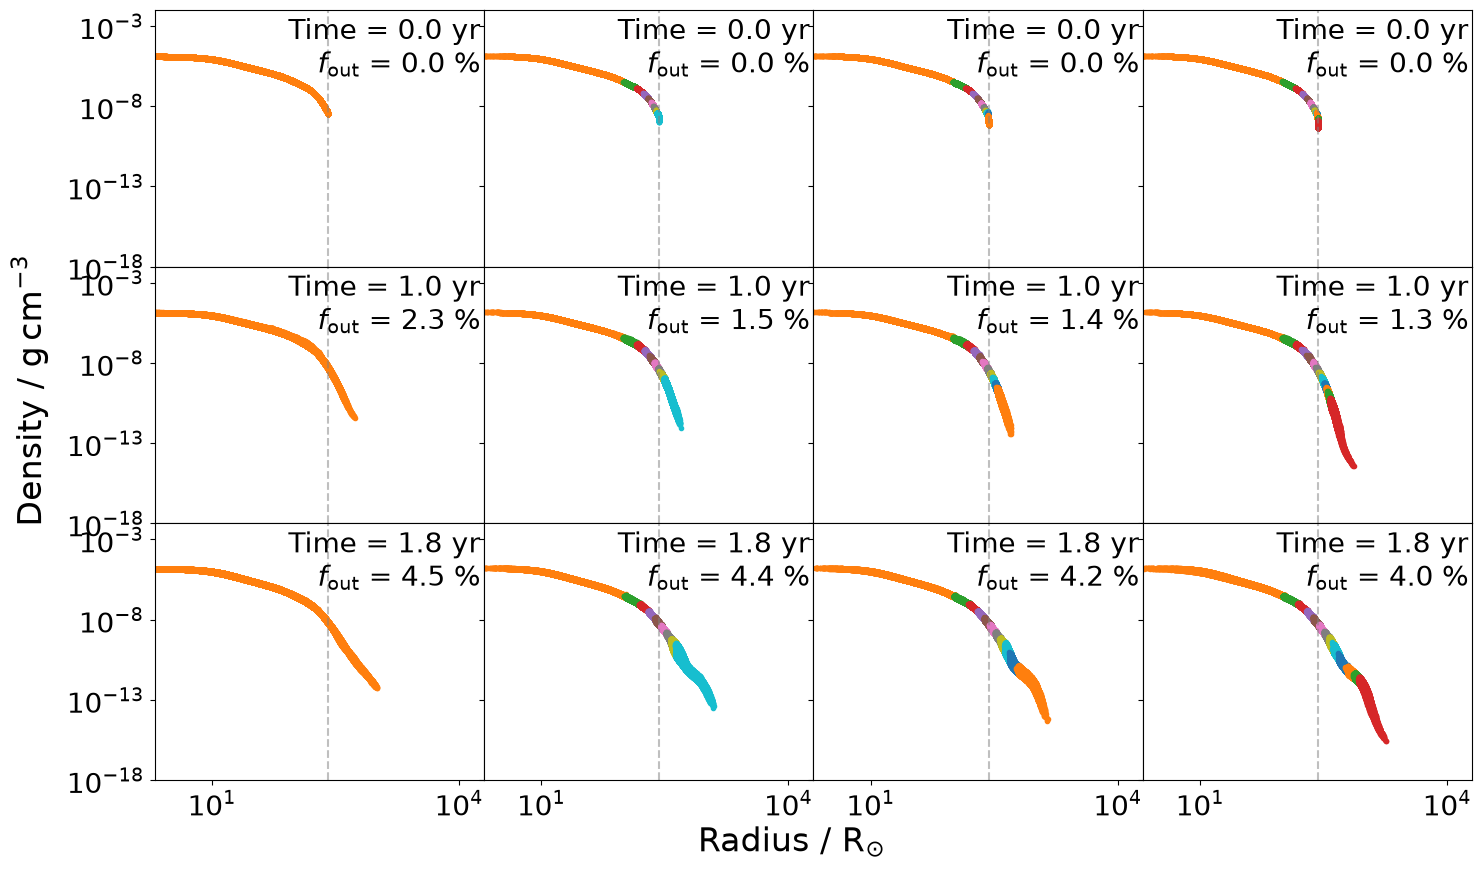

In [18]:
fig, axes = plot_rho_vs_rcom_panels()

#### Debug

In [11]:
do_debug = False
if do_debug:
    job_profile = JOB_PROFILES_DICT['2ma-star--mfrac-p2-12']
    mpdf = mpdf_read(job_profile['job_name'],  0, mpdf=None, ieos=10, params=job_profile['params'], calc_params=[], verbose=1)
    rho0 = np.min(mpdf.data['gas']['rho'].min())
    mpdf = mpdf_read(job_profile['job_name'], 800, mpdf=mpdf, ieos=10, params=job_profile['params'], calc_params=[], verbose=1)
    mpdf.data['gas']['RCoM'] = (mpdf.data['gas'][['x', 'y', 'z']]**2).sum(axis=1)**0.5
    sdf_sorted = mpdf.data['gas'].sort_values(by='RCoM')

    mask = sdf_sorted['rho'] > rho0
    mass = np.where(mask, sdf_sorted['mass'], 0)
    mfrac = np.cumsum(mass) / np.sum(mass)
    mask = mask & (mfrac > 0.995)